# HanuAi ML Assessment — Task 2: Advanced EDA & Text Mining
**Dataset:** `Hanuai_task2_assignment.csv` — 1,000 warranty/service events for MY2020 vehicles (infotainment / audio / display complaints).

**Workflow**
1. Data assessment & cleaning (types, missing values, duplicates, inconsistencies)
2. EDA on critical columns (summary statistics + distributions)
3. Text mining: free-text → structured entity tags (components, conditions, triggers, fixes, error-code/process flags)
4. Issue categorisation (higher-level "type of issue")
5. Trends / pattern analysis
6. Clustering (K-Means on TF-IDF) + topic modelling (LDA) → root-cause hypotheses
7. Exports (tagged CSV / Excel) and business insights

Every step is commented so a reviewer can follow the reasoning.

In [1]:
# ---- Imports & global config ----
import re, ast, warnings, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.titleweight": "bold"})
RNG = 42
DATA_PATH = os.environ.get("T2_DATA", "Hanuai_task2_assignment.csv")
FIG_DIR = os.environ.get("T2_FIG", "figures"); os.makedirs(FIG_DIR, exist_ok=True)
def savefig(name):
    plt.tight_layout(); plt.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")

## 1. Data assessment

In [2]:
raw = pd.read_csv(DATA_PATH, encoding="utf-8")
df = raw.copy()
print("Shape (rows, cols):", df.shape)
print("\n--- dtypes & non-null counts ---")
print(df.dtypes.to_frame("dtype").join(df.notna().sum().to_frame("non_null")).join(df.nunique().to_frame("n_unique")))

Shape (rows, cols): (1000, 20)

--- dtypes & non-null counts ---
                     dtype  non_null  n_unique
Event id               str      1000      1000
Opened date            str      1000       397
CAUSAL_VERBATIM        str       999       944
CORRECTION_VERBATIM    str      1000       952
CUSTOMER_VERBATIM      str      1000       990
BUILD_DATE             str      1000        37
BUILD_PLANT_DESC       str      1000         8
CAUSAL_CD_DESC         str       997        38
COMPLAINT_CD_DESC      str      1000         9
IN_USE_DATE            str       999       285
MAKE                   str      1000         4
MODEL                  str      1000        23
MODLYR               int64      1000         1
PLANT                  str      1000         8
Trigger                str         5         2
Failure Component      str         5         5
Failure Condition      str         5         5
Additional Context     str         5         2
Fix Component          str         5      

In [3]:
# Missing values (count and %)
miss = df.isna().sum().to_frame("missing"); miss["pct"] = (miss.missing / len(df) * 100).round(1)
print(miss[miss.missing > 0])

# Duplicate checks: exact rows, event ids, and near-duplicate narratives
print("\nExact duplicate rows      :", df.duplicated().sum())
print("Duplicate Event ids       :", df["Event id"].duplicated().sum())
dup_txt = df.duplicated(subset=["CUSTOMER_VERBATIM", "CAUSAL_VERBATIM", "CORRECTION_VERBATIM"], keep=False).sum()
print("Rows sharing identical customer+causal+correction text:", dup_txt)

                    missing   pct
CAUSAL_VERBATIM           1   0.1
CAUSAL_CD_DESC            3   0.3
IN_USE_DATE               1   0.1
Trigger                 995  99.5
Failure Component       995  99.5
Failure Condition       995  99.5
Additional Context      995  99.5
Fix Component           995  99.5
Fix Condition           995  99.5

Exact duplicate rows      : 0
Duplicate Event ids       : 0
Rows sharing identical customer+causal+correction text: 0


**Observations from the assessment**
* 1,000 unique events, no exact duplicates → no rows removed.
* Six *structured* columns (`Trigger`, `Failure Component`, `Failure Condition`, `Additional Context`, `Fix Component`, `Fix Condition`) are **99.5 % empty** — only 5 rows are hand-labelled. They are the *target schema* that text mining must populate for all 1,000 rows.
* `MODLYR` is constant (2020) → no analytical value; `PLANT` and `BUILD_PLANT_DESC` are 1-to-1 duplicates of each other.
* `COMPLAINT_CD_DESC` contains non-breaking spaces (`\xa0`) creating a spurious extra category.
* Dates are strings in 2 different formats (`m/d/YYYY` vs ISO-8601 timestamp).
* A few `CUSTOMER_VERBATIM` values are just the complaint code text (e.g. "Audio Entertainment Navigation Other issues") – no real customer narrative.
* Free text is noisy: upper/lower case mix, missing spaces between sentences (e.g. `"...concernrequires more time"`), numbers/IDs scrubbed (DTC numbers are blank), and ~2 KB of text for the longest records.

## 2. Data cleaning

In [4]:
# 2.1 Standardise text-ish categorical columns (strip NBSP / double spaces)
def clean_ws(s):
    return s.str.replace("\xa0", " ", regex=False).str.replace(r"\s+", " ", regex=True).str.strip()
for c in ["COMPLAINT_CD_DESC", "CAUSAL_CD_DESC", "BUILD_PLANT_DESC", "MAKE", "MODEL", "PLANT"]:
    df[c] = clean_ws(df[c])
print("COMPLAINT_CD_DESC categories after cleaning:", df.COMPLAINT_CD_DESC.nunique())

# 2.2 Parse the three date columns into a single datetime type
df["opened_date"] = pd.to_datetime(df["Opened date"], format="%m/%d/%Y")
df["build_date"]  = pd.to_datetime(df["BUILD_DATE"],  utc=True).dt.tz_localize(None)
df["in_use_date"] = pd.to_datetime(df["IN_USE_DATE"], utc=True).dt.tz_localize(None)

# 2.3 Missing-value imputation
#   * IN_USE_DATE (1 missing): build_date + median build→in-use lag (robust to outliers)
lag = (df.in_use_date - df.build_date).dt.days
df["in_use_imputed_flag"] = df.in_use_date.isna()
df.loc[df.in_use_date.isna(), "in_use_date"] = df.build_date + pd.to_timedelta(lag.median(), unit="D")
#   * CAUSAL_CD_DESC (3 missing): impute with the most frequent causal code *within the same complaint code*
#     (conditional-mode imputation); flag them so the imputation is transparent
df["causal_imputed_flag"] = df.CAUSAL_CD_DESC.isna()
mode_by_complaint = df.groupby("COMPLAINT_CD_DESC")["CAUSAL_CD_DESC"].agg(lambda s: s.mode().iat[0] if s.notna().any() else np.nan)
df["CAUSAL_CD_DESC"] = df.CAUSAL_CD_DESC.fillna(df.COMPLAINT_CD_DESC.map(mode_by_complaint)).fillna("Unknown")
#   * CAUSAL_VERBATIM (1 missing): free text → empty string (a missing narrative is not imputable)
df["CAUSAL_VERBATIM"] = df.CAUSAL_VERBATIM.fillna("")

# 2.4 Flag uninformative customer narratives (text == complaint code description)
norm = lambda s: re.sub(r"[^a-z]", "", s.lower())
df["customer_text_is_placeholder"] = [norm(a) == norm(b) for a, b in zip(df.CUSTOMER_VERBATIM, df.COMPLAINT_CD_DESC)]
print("Placeholder customer narratives:", df.customer_text_is_placeholder.sum())

# 2.5 Derived numeric features (needed for statistics)
df["days_build_to_inuse"] = (df.in_use_date - df.build_date).dt.days            # delivery / dealer-stock lag
df["days_in_service_raw"] = (df.opened_date - df.in_use_date).dt.days            # time-in-service at failure (raw)
df["opened_before_in_use"] = df.days_in_service_raw < 0                       # inconsistency: claim opened BEFORE in-service date
df["days_in_service"]     = df.days_in_service_raw.where(~df.opened_before_in_use)  # valid values only; negatives -> NaN (excluded from TIS statistics)
df["open_month"]          = df.opened_date.dt.to_period("M").dt.to_timestamp()
df["customer_len"]        = df.CUSTOMER_VERBATIM.str.len()
df["causal_len"]          = df.CAUSAL_VERBATIM.str.len()
df["correction_len"]      = df.CORRECTION_VERBATIM.str.len()
print(f"Inconsistent rows (opened before in-use date): {df.opened_before_in_use.sum()} ({df.opened_before_in_use.mean():.1%}); median gap = {df.days_in_service_raw[df.opened_before_in_use].median():.0f} days")
print("→ kept in the dataset and flagged; excluded from time-in-service statistics (likely pre-delivery defects found at dealer stock, or date-entry errors).")

# 2.6 Drop zero-information / redundant columns from the analytical frame
df = df.drop(columns=["MODLYR", "PLANT"])      # constant column; PLANT duplicates BUILD_PLANT_DESC
df = df.rename(columns={"BUILD_PLANT_DESC": "plant"})

COMPLAINT_CD_DESC categories after cleaning: 9
Placeholder customer narratives: 8
Inconsistent rows (opened before in-use date): 76 (7.6%); median gap = -56 days
→ kept in the dataset and flagged; excluded from time-in-service statistics (likely pre-delivery defects found at dealer stock, or date-entry errors).


In [5]:
# 2.7 Handle the sparse hand-labelled columns: keep the 5 gold labels aside as a validation set
struct_cols = ["Trigger", "Failure Component", "Failure Condition", "Additional Context", "Fix Component", "Fix Condition"]
gold = df[df.Trigger.notna()][["Event id"] + struct_cols].copy()
for c in struct_cols:
    gold[c] = gold[c].apply(ast.literal_eval)
print("Gold-labelled examples kept for validation:", len(gold))
df = df.drop(columns=struct_cols)
print("Clean frame shape:", df.shape)

Gold-labelled examples kept for validation: 5
Clean frame shape: (1000, 26)


## 3. Exploratory analysis of critical columns
**Critical columns for stakeholders** (why): `MODEL`, `MAKE`, `plant` (where do failures come from → quality owner); `COMPLAINT_CD_DESC` (what the customer feels); `CAUSAL_CD_DESC` (what the technician found); `opened_date` (trend); `days_in_service` (early-life vs wear-out); the three verbatim fields (richest information).

In [6]:
num_cols = ["days_build_to_inuse", "days_in_service", "customer_len", "causal_len", "correction_len"]  # days_in_service = valid rows only
summary = df[num_cols].agg(["count", "mean", "median", "std", "min", "max", "skew"]).T.round(1)
print(summary)

                      count   mean  median    std  min     max  skew
days_build_to_inuse  1000.0  121.1    91.0   99.5  1.0   596.0   1.3
days_in_service       924.0  241.7   228.0  161.0  0.0   615.0   0.3
customer_len         1000.0  100.4    79.0   80.9  5.0   799.0   3.0
causal_len           1000.0  140.1    77.0  182.9  0.0  1890.0   3.4
correction_len       1000.0  179.8    97.5  222.8  8.0  1888.0   3.0


Valid time-in-service rows: 924 | within first 90 days: 21.1% | within 180 days: 42.6% | within 1 year: 75.0%


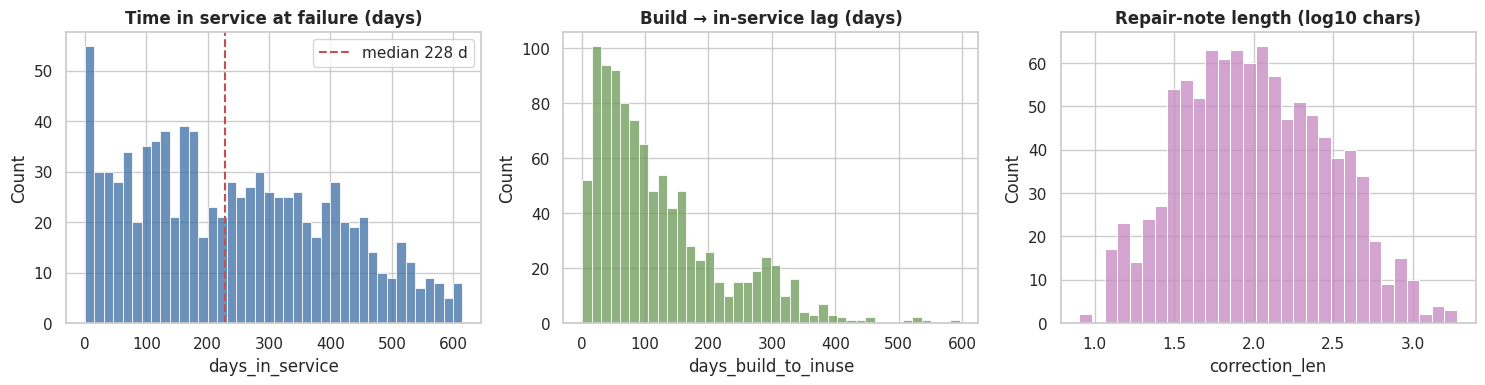

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df.days_in_service, bins=40, ax=axes[0], color="#3b6ea5"); axes[0].axvline(df.days_in_service.median(), color="r", ls="--", label=f"median {df.days_in_service.median():.0f} d"); axes[0].legend()
axes[0].set_title("Time in service at failure (days)")
sns.histplot(df.days_build_to_inuse, bins=40, ax=axes[1], color="#6a9955"); axes[1].set_title("Build → in-service lag (days)")
sns.histplot(np.log10(df.correction_len), bins=30, ax=axes[2], color="#c586c0"); axes[2].set_title("Repair-note length (log10 chars)")
savefig("01_numeric_distributions"); plt.show()
tis = df.days_in_service.dropna()
print(f"Valid time-in-service rows: {len(tis)} | within first 90 days: {(tis<=90).mean():.1%} | within 180 days: {(tis<=180).mean():.1%} | within 1 year: {(tis<=365).mean():.1%}")

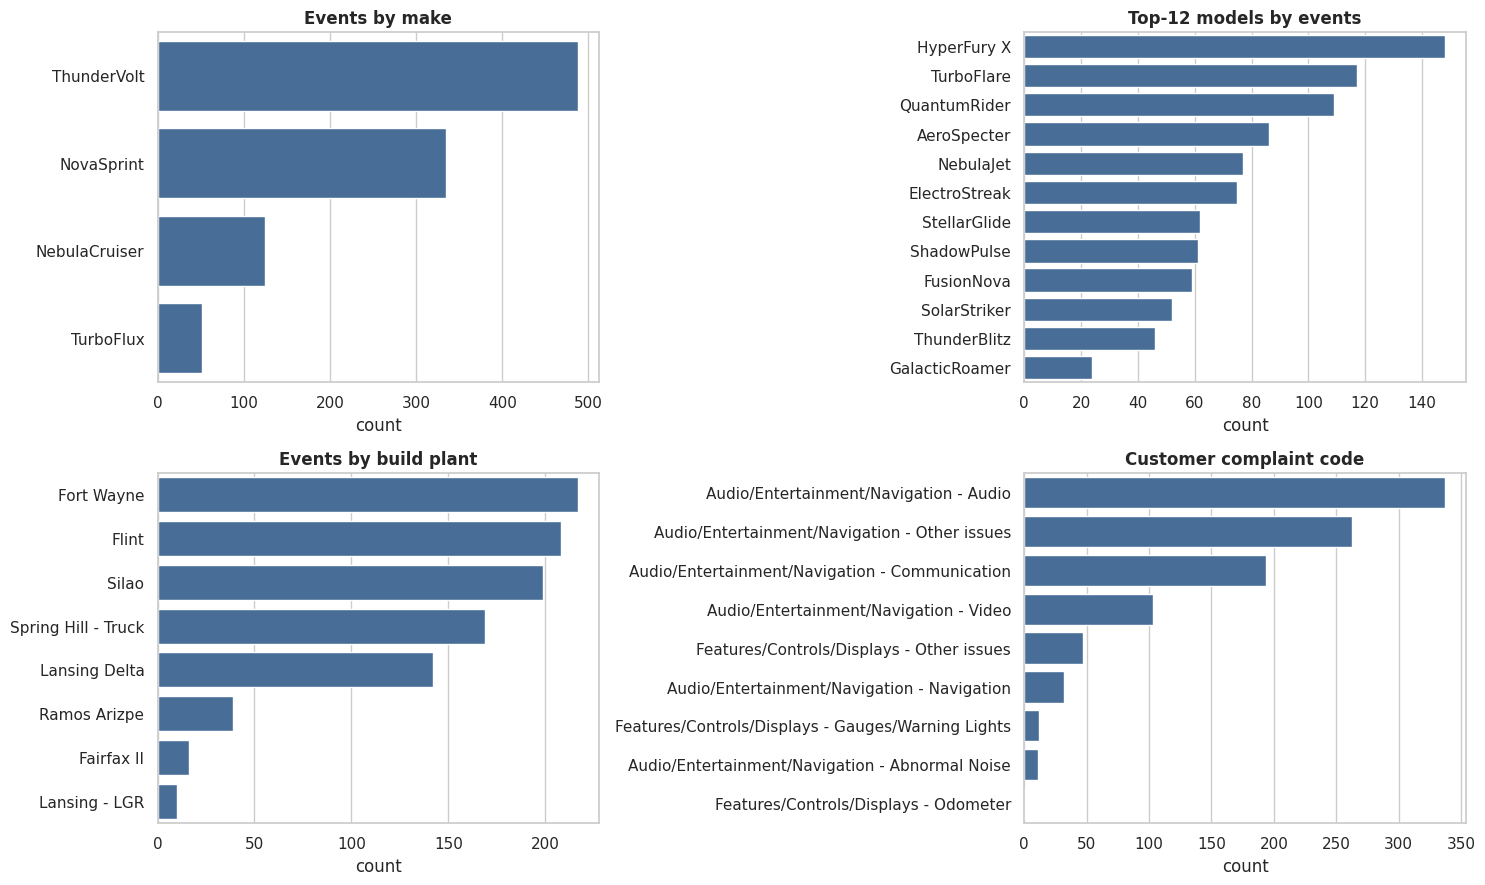

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
order = df.MAKE.value_counts().index
sns.countplot(data=df, y="MAKE", order=order, ax=axes[0,0], color="#3b6ea5"); axes[0,0].set_title("Events by make")
order = df.MODEL.value_counts().index[:12]
sns.countplot(data=df, y="MODEL", order=order, ax=axes[0,1], color="#3b6ea5"); axes[0,1].set_title("Top-12 models by events")
order = df.plant.value_counts().index
sns.countplot(data=df, y="plant", order=order, ax=axes[1,0], color="#3b6ea5"); axes[1,0].set_title("Events by build plant")
order = df.COMPLAINT_CD_DESC.value_counts().index
sns.countplot(data=df, y="COMPLAINT_CD_DESC", order=order, ax=axes[1,1], color="#3b6ea5"); axes[1,1].set_title("Customer complaint code")
for a in axes.ravel(): a.set_ylabel("")
savefig("02_categorical_distributions"); plt.show()

causal_family
Module/Component                          827
Wiring/Electrical/Sensors                  93
Other                                      67
Rotating Part                               7
Surface (interior)                          4
Interface (Gasket; Seal; Hose; Weld..)      1
Fastener                                    1
Name: count, dtype: int64 

CAUSAL_CD_DESC
Module/Component-No/Incorrect Communication             380
Module/Component-Shorted                                237
Module/Component-Registers Incorrectly                  121
Wiring/Electrical/Sensors-No/Incorrect Communication     50
Module/Component-Broken                                  41
Wiring/Electrical/Sensors-Shorted                        23
Other-Campaign/ Tech Bulletin                            22
Other-Follow operation                                   22
Other-No trouble found - adjusted / reprogrammed         21
Wiring/Electrical/Sensors-Registers Incorrectly          12
Name: count, dtype: i

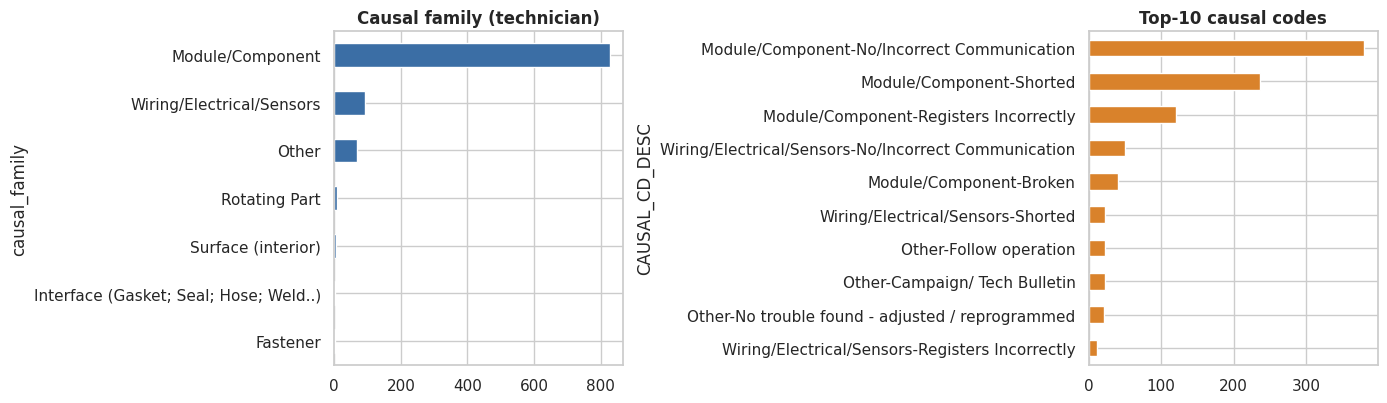

In [9]:
# Technician "causal code" is long-tailed → group into 6 families for readability (family = text before the first '-')
df["causal_family"] = df.CAUSAL_CD_DESC.str.split("-").str[0].str.strip()
fam = df.causal_family.value_counts()
print(fam, "\n")
print(df.CAUSAL_CD_DESC.value_counts().head(10))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
fam.sort_values().plot.barh(ax=ax[0], color="#3b6ea5"); ax[0].set_title("Causal family (technician)")
df.CAUSAL_CD_DESC.value_counts().head(10).sort_values().plot.barh(ax=ax[1], color="#d9822b"); ax[1].set_title("Top-10 causal codes")
savefig("03_causal_codes"); plt.show()

**EDA takeaways**
* The data is infotainment-dominated: 94 % of events carry an Audio/Entertainment/Navigation complaint code, only 6 % are generic dash/display/controls.
* All vehicles share one narrow build window (1 Aug – 7 Sep 2019, 84 % built in August) → this is a *single production cohort*; we only have claims, no production volumes, so we can compare **shares**, not failure **rates**.
* Failures are *early-life*: the median claim arrives ~7.5 months after the in-service date, 43 % within 6 months and 75 % within one year for a product that should last the vehicle's life — a hallmark of manufacturing / software-release defects rather than wear-out.
* 7.6 % of claims carry an *opened date earlier than the in-service date* — either pre-delivery defects found at the dealer, or date-entry errors; both are data-quality / PDI signals.
* Technician causal codes are dominated by **"Module/Component – No/Incorrect Communication" and "Shorted"** – i.e. electronic module faults rather than mechanical ones.

## 4. Text mining — free text → structured tags
**Free-text columns identified:** `CUSTOMER_VERBATIM` (complaint as told by the customer), `CAUSAL_VERBATIM` (technician's diagnosis), `CORRECTION_VERBATIM` (repair performed).

**Approach:** a transparent, auditable *dictionary / regex entity extractor* (rule-based NER), designed from term-frequency analysis of the corpus and the 5 gold examples in the file. Rationale: (a) no network/GPU needed, (b) deterministic, explainable to stakeholders, (c) the vocabulary is a narrow technical domain where a curated lexicon beats generic NER. A section at the end shows how an open-source LLM could replace/extend it.

Tags produced (mirroring the target schema in the sheet): **Failure Component**, **Failure Condition**, **Trigger**, **Additional Context**, **Fix Component**, **Fix Condition** + process flags (bulletin/TAC case referenced, DTC mentioned…).

In [10]:
# ---- Pre-processing helpers ----
def normalise(text):
    """Lower-case, replace separators, collapse whitespace."""
    t = str(text).lower()
    t = re.sub(r"[_/\\|]+", " ", t)
    t = re.sub(r"[\u2019']", " ", t)            # don't -> don t
    t = re.sub(r"\s+", " ", t)
    return t.strip()

# Negation / non-event phrases that would otherwise create FALSE tags
# e.g. "unable to program the radio" must not become a 'Programmed' fix; "no codes set" is not a DTC symptom; "USB programming" is not a USB-port fault.
NEG_PATTERNS = [
    r"(unable|not able|couldn t|could not|can not|cannot|can t|would not|will not|didn t|did not|failed) to (\w+ ){0,2}(program\w*|reprogram\w*|flash\w*|updat\w*|duplicate|verify|replicate|find)",
    r"no (new |updated |further |latest |available )*(software|update|updates|programming|reprogramming)( (update|updates|available|found))*",
    r"usb (programming|update|updates|stick|drive|flash|download)",
    r"(software|updates?|calibrations?) (is |are )?(up to date|current|latest|already)",
    r"no (dtc|dtcs|codes?)( set| found| present| stored| were| in)*",
]
def strip_neg(t):
    t = normalise(t)
    for p in NEG_PATTERNS: t = re.sub(p, " ", t)
    return re.sub(r"\s+", " ", t)

# ---- Entity lexicons: tag -> regex  (English + the French/Spanish terms found in the corpus) ----
COMPONENT_LEX = {
    "Radio / Head Unit":      r"\b(radio|head ?unit|infotainment|ihu|hmi|audio unit|stereo|media unit|mylink|cue|receiver)\b",
    "Display / Touchscreen":  r"\b(screen|display|touch ?screen|lcd|monitor|pantalla|ecran|écran|afficheur)\b",
    "Backup Camera":          r"\b(back ?up camera|rear (view )?camera|reverse camera|rvc|camera|camara|cámara|caméra|camera de recul)\b",
    "Amplifier / Speakers":   r"\b(amp|amplifier|speaker|speakers|subwoofer|woofer|bose|haut ?parleur\w*|bocina\w*)\b",
    "Antenna / Reception":    r"\b(antenna|antenne|antena|reception|coax\w*|satellite|sirius|xm|siriusxm|am fm|signal)\b",
    "USB / Aux Port":         r"\b(usb|aux|auxiliary|media hub|usb port)\b",
    "Phone / Bluetooth":      r"\b(bluetooth|carplay|android auto|pairing|paired|pair|hands ?free|microphone|phone|telephone|telefono|téléphone|appel\w*)\b",
    "Navigation / SD Card":   r"\b(navigation|nav|gps|sd card|map|maps|navegacion|navegación)\b",
    "OnStar / Telematics":    r"\b(onstar|telematics|tcim|tcu|wifi|wi fi|hotspot|lte|4g)\b",
    "Steering-Wheel / Controls": r"\b(steering wheel|swc|knob|knobs|volante|volant)\b|\b(control|controls) (buttons?|panel|switch)\b|\bbuttons?\b",
    "Instrument Cluster":     r"\b(cluster|ipc|gauge|gauges|dic|driver information center|odometer|odometre|warning light)\b",
    "Wiring / Connector":     r"\b(wire|wires|wiring|harness|connector|connectors|terminal|terminals|pins?|circuit|circuits|ground|grounds|cable|cables|ethernet|can ?bus|data bus|splice)\b",
    "Software / Firmware":    r"\b(software|firmware|updates?|calibrations?|reprogram\w*|programm\w*|sps|flash\w*|ota|logiciel|mise a jour|mise à jour)\b",
    "Battery / Power Supply": r"\b(battery|batterie|bateria|voltage|fuse|power supply|parasitic|drain)\b",
}
CONDITION_LEX = {
    "Inoperative / Dead":       r"\b(inop|inoperative|not working|does not work|doesn t work|dead|no operation|stopped working|quit working|won t work|no function|not functioning|no funciona|ne fonctionne pas|non fonctionnel)\b",
    "Black / Blank Screen":     r"\b(black screen|blank screen|screen (is |goes |went |stays |turns |comes )?(black|blank|off|dark)|blank|goes black|negra|obscura|noir|noire|no image|no display)\b",
    "No Sound / Audio Loss":    r"\b(no sound|no audio|no volume|can not hear|cannot hear|sound (cuts?|cutting|drops?|goes)|cuts? out|cutting out|mutes?|muted|audio (loss|drops?|cuts?)|lost audio|sin sonido|sin audio|pas de son|sans son|doesn t play)\b",
    "Intermittent":             r"\b(intermittent|intermittently|intermittant|sometimes|randomly|random|on and off|comes and goes|occasionally|at times|parfois|aleatori\w*|intermitente)\b",
    "Reboot / Restart / Reset": r"\b(reboot\w*|restarts?|re ?starting|resets?|resetting|shuts? (itself )?(off|down)|turns? (itself )?off|powers? off|logo|bow tie|triangle|factory (agreements?|settings?))\b",
    "Freeze / Lag / Unresponsive": r"\b(freez\w*|frozen|lag|laggy|slow|unresponsive|no response|stuck|hangs?|not respon\w*|irresponsive|stays on|will not turn off|won t turn off|does not shut off)\b",
    "Communication Loss / DTC": r"\b(lost comm\w*|no comm\w*|loss of comm\w*|not communicating|incorrect communication|can ?bus|ethernet|offline|lost communication|communication (error|loss|fault|issue|problem)|comm loss|u[0-9a-f]{4}|dtcs?)\b",
    "Noise / Static / Distortion": r"\b(noise|static|buzz\w*|crackl\w*|hiss\w*|distort\w*|popping|humming|whin\w*|ruido)\b",
    "Connectivity Failure (BT/USB/Phone)": r"\b(won t connect|not connect\w*|will not connect|fails? to connect|disconnect\w*|not pair\w*|no connection|can t pair|drops? (the )?(call|connection)|dropped call|no calls?|cannot (make|receive) calls?)\b",
    "Poor / No Reception":      r"\b(no reception|poor reception|weak signal|no signal|lost signal|signal lost|no stations?|no channels?|loses? (the )?(station|signal))\b",
    "Error Message":            r"\b(error|erreur|error message|displays? (an? )?(error|message)|message (says|reads|displayed)|warning message|read error|general inaccuracy)\b",
    "Internal Fault / Short":   r"\b(internal (fault|failure|malfunction|short|issue|problem|defect)|internally|shorted|faulty|defective|internal)\b",
    "Display Glitch / Distortion": r"\b(flicker\w*|flash(es|ing)?|vertical lines|horizontal lines|lines on|distorted|dim|dimming|glitch\w*|garbled|pixel\w*|wrong language|language)\b",
}
TRIGGER_LEX = {
    "While Driving":           r"\b(driving|while driv\w*|on the road|highway|in motion|at speed|roulait|conduciendo|en marcha)\b",
    "On Start-up / Ignition":  r"\b(start ?up|starting|start the (vehicle|car|truck)|on start|ignition|turn(ed|ing)? on|key on|power on|cold start|initial|remote start|demarrage|arranque)\b",
    "In Reverse / Camera Use": r"\b(reverse|backing|back ?up|rear view|reversa|recul)\b",
    "Phone / Device Connected": r"\b(phone|bluetooth|carplay|android auto|usb|pairing|paired|connecting|telephone)\b",
    "After Software Update":   r"\b(after (the |a )?(software )?(update|reprogram\w*|programming|flash)|since (the )?update|following (the )?(update|bulletin)|depuis la mise)\b",
    "Weather / Temperature":   r"\b(rain|wet|cold|hot|heat|temperature|weather|humid\w*|freezing|snow)\b",
    "Door / Key-off event":    r"\b(door|key off|turn(ed|ing)? off|shut ?down|parked|overnight|sitting|after (vehicle )?(is )?(off|shut off))\b",
    "Volume / Control Input":  r"\b(volume|change (station|source|channel)|switch(ing)? (station|source|channel)|steering wheel|press\w*|touch(ing)? (the )?screen)\b",
}
CONTEXT_LEX = {
    "Customer-reported Intermittent Concern": r"\b(intermittent\w*|intermittant|sometimes|randomly|at times)\b",
    "Unable to Duplicate / No Fault Found":   r"\b(unable to (duplicate|verify|replicate|recreate)|could not (duplicate|verify)|no fault found|no trouble found|nff|not duplicated|can ?not duplicate|can t duplicate|concern not (present|duplicated)|cnd|problem not present)\b",
    "Repeat Repair / Previous Visit":         r"\b(previous\w*|repeat|second time|returned|already (replaced|repaired|diagnosed)|last (visit|time)|came back|again|still (has|having|happening|present|not|does|doing|the same))\b",
    "Multiple Symptoms":                      r"\b(also|multiple|several|as well as|along with)\b",
    "Delivery / New Vehicle (PDI)":           r"\b(at delivery|delivery|new vehicle|pdi|pre ?delivery|dealer stock|dealer lot|on the lot|demo)\b",
    "Bulletin / TAC / Techline Referenced":   r"\b(bulletin|tac|techline|tech line|tech assist\w*|case #?|campaign|gds ?2?|engineering)\b",
}
FIXCOMP_LEX = {
    "Radio / Head Unit":     r"\b(radio|head ?unit|infotainment|ihu|audio unit|receiver|hmi|cue)\b",
    "Display / Touchscreen": r"\b(screen|display|touch ?screen)\b",
    "Backup Camera":         r"\b(camera)\b",
    "Amplifier / Speakers":  r"\b(amp|amplifier|speaker|speakers|subwoofer)\b",
    "Antenna / Cable":       r"\b(antenna|coax\w*|cable)\b",
    "USB / Media Hub":       r"\b(usb|media hub|aux)\b",
    "Telematics / OnStar":   r"\b(onstar|telematics|tcim|tcu)\b",
    "Wiring / Connector":    r"\b(wire|wires|wiring|harness|connector|connectors|terminal|pin|pins|ground|grounds|splice\w*)\b",
    "Software (SPS)":        r"\b(sps|software|firmware|calibrations?|flash\w*|reprogram\w*|programm\w*)\b",
    "Battery / Fuse":        r"\b(battery|fuse|relay)\b",
    "SD Card / Navigation":  r"\b(sd card|navigation|nav)\b",
}
FIXACT_LEX = {
    "Replaced":            r"\b(replac\w*|r r|r&r|exchang\w*|installed new|new (radio|unit|module|part|screen|display|camera|antenna)|swapped|remplac\w*|reemplaz\w*)\b",
    "Programmed / Reflashed": r"\b(programm\w*|reprogram\w*|reflash\w*|flash\w*|updated software|software update|calibrat\w*|sps)\b",
    "Repaired":            r"\b(repair\w*|spliced|resoldered|soldered|re ?terminat\w*|re ?pinn\w*|straighten\w*|tighten\w*|re ?rout\w*|re ?seat\w*|secured)\b",
    "Reset / Relearn":     r"\b(reset|relearn\w*|re ?initializ\w*|ran (the )?(learn|relearn))\b",
    "Cleaned":             r"\b(clean\w*|lubricat\w*|dielectric)\b",
    "Adjusted":            r"\b(adjust\w*|aligned|alignment)\b",
    "Inspected / No Fault Found": r"\b(no fault found|nff|no trouble found|nothing wrong|operating (as designed|normally)|working normally|operates normally|concern not present|cnd|normal operation)\b",
}
ACTION_CLAUSE = r"replac|exchang|install|r&r|r r |repair|splic|solder|reprogram|program|reflash|flash|calibrat|updat|secure|tighten|clean|adjust|remplac|reemplaz"

def extract(text, lex, strip=True):
    t = strip_neg(text) if strip else normalise(text)
    return [tag for tag, pat in lex.items() if re.search(pat, t)]

def action_text(text):
    """Keep only the clauses of a repair note that describe an action performed (replace/program/repair…)
    so components that were merely *inspected/tested* are not tagged as fixed."""
    clauses = re.split(r"[.;,:]| and | then | per | after ", strip_neg(text))
    return " . ".join(c for c in clauses if re.search(ACTION_CLAUSE, c))

# Language flag (the corpus contains French- and Spanish-language records from Canadian/Mexican plants)
FR = r"\b(le|la|les|du|des|est|pas|écran|ecran|avec|pour|une|dans|client|probleme|problème|sur|aucun|mise à jour|fonctionne)\b"
ES = r"\b(el|los|las|pantalla|cliente|con|por|para|sin|falla|negra|vehiculo|vehículo|funciona|del|una|que)\b"
alltext_raw = (df.CUSTOMER_VERBATIM + " " + df.CAUSAL_VERBATIM + " " + df.CORRECTION_VERBATIM)
fr_n = alltext_raw.apply(lambda s: len(re.findall(FR, s, flags=re.I))); es_n = alltext_raw.apply(lambda s: len(re.findall(ES, s, flags=re.I)))
df["language"] = np.select([(fr_n >= 3) & (fr_n > es_n), (es_n >= 3) & (es_n > fr_n)], ["French", "Spanish"], "English")
print(df.language.value_counts().to_dict())

# Customer text feeds symptom entities, technician text the diagnosis, correction text the fix entities
df["cust_text"]    = df.CUSTOMER_VERBATIM.where(~df.customer_text_is_placeholder, "")
df["diag_text"]    = df.CAUSAL_VERBATIM
df["symptom_text"] = df.cust_text + " . " + df.diag_text
df["all_text"]     = df.cust_text + " . " + df.diag_text + " . " + df.CORRECTION_VERBATIM

{'English': 984, 'French': 12, 'Spanish': 4}


In [11]:
df["failure_component"]  = df.symptom_text.apply(lambda t: extract(t, COMPONENT_LEX))
df["failure_condition"]  = df.symptom_text.apply(lambda t: extract(t, CONDITION_LEX))
df["trigger"]            = df.cust_text.apply(lambda t: extract(t, TRIGGER_LEX))
df["additional_context"] = df.all_text.apply(lambda t: extract(t, CONTEXT_LEX, strip=False))
df["fix_component"]      = df.CORRECTION_VERBATIM.apply(lambda t: extract(action_text(t), FIXCOMP_LEX, strip=False))
df["fix_condition"]      = df.CORRECTION_VERBATIM.apply(lambda t: extract(t, FIXACT_LEX))

# Defaults used by the gold labels in the supplied sheet ("No Additional Context" etc.)
df["trigger"]            = df.trigger.apply(lambda l: l or ["No Additional Functionality"])
df["additional_context"] = df.additional_context.apply(lambda l: l or ["No Additional Context"])

# Primary (single) component = what the *customer* complained about first; else what the technician blames; else the head unit.
# Wiring / software / battery are *causes*, so they are skipped when looking for the symptom location.
PRIORITY = ["Backup Camera", "Navigation / SD Card", "Phone / Bluetooth", "USB / Aux Port", "OnStar / Telematics", "Antenna / Reception",
            "Amplifier / Speakers", "Instrument Cluster", "Steering-Wheel / Controls", "Display / Touchscreen", "Radio / Head Unit"]
def first_hit(text):
    t = strip_neg(text)
    for tag in PRIORITY:
        if re.search(COMPONENT_LEX[tag], t): return tag
    return None
df["cust_component"]    = df.cust_text.apply(first_hit)
df["primary_component"] = [c or first_hit(d) or "Radio / Head Unit" for c, d in zip(df.cust_component, df.diag_text)]

# Process / identifier flags (regex-based entity extraction of codes & references) – DTC numbers are scrubbed in the data, so we flag *mentions*
df["mentions_dtc"]        = df.all_text.str.contains(r"\bdtcs?\b|\bu[0-9a-f]{4}\b|\bb[0-9a-f]{4}\b", case=False, regex=True)
df["mentions_bulletin"]   = df.all_text.str.contains(r"bulletin|campaign|\btsb\b", case=False, regex=True)
df["mentions_tac_case"]   = df.all_text.str.contains(r"\btac\b|techline|tech line|case #|gm case|tech assist", case=False, regex=True)
df["fault_not_duplicated"]= df.all_text.apply(lambda t: bool(re.search(CONTEXT_LEX["Unable to Duplicate / No Fault Found"], normalise(t))))
df["part_ordered_wait"]   = df.all_text.str.contains(r"on order|order(ed)? (new|part)|waiting (for|on) part|back ?order|please order|need to order|parts? (on|ordered)", case=False, regex=True)
print(df[["mentions_dtc","mentions_bulletin","mentions_tac_case","fault_not_duplicated","part_ordered_wait"]].mean().round(3).rename("share_of_events"))

mentions_dtc            0.141
mentions_bulletin       0.095
mentions_tac_case       0.317
fault_not_duplicated    0.022
part_ordered_wait       0.037
Name: share_of_events, dtype: float64


In [12]:
# Coverage and frequency of every extracted entity
def flat_counts(col): return pd.Series(Counter(x for l in df[col] for x in l)).sort_values(ascending=False)
for col in ["failure_component", "failure_condition", "trigger", "additional_context", "fix_component", "fix_condition"]:
    c = flat_counts(col)
    print(f"\n=== {col}  | coverage (events with ≥1 tag): {(df[col].str.len()>0).mean():.1%} ===")
    print(c.to_string())
print("\nPrimary component:\n", df.primary_component.value_counts().to_string())


=== failure_component  | coverage (events with ≥1 tag): 99.1% ===
Radio / Head Unit            932
Display / Touchscreen        423
Wiring / Connector           257
Software / Firmware          229
Antenna / Reception          196
Backup Camera                131
Phone / Bluetooth             83
Navigation / SD Card          72
OnStar / Telematics           60
USB / Aux Port                58
Battery / Power Supply        57
Steering-Wheel / Controls     46
Amplifier / Speakers          34
Instrument Cluster            18

=== failure_condition  | coverage (events with ≥1 tag): 86.1% ===
Internal Fault / Short                 373
Inoperative / Dead                     250
Intermittent                           201
Black / Blank Screen                   191
Communication Loss / DTC               181
Reboot / Restart / Reset               141
No Sound / Audio Loss                  129
Freeze / Lag / Unresponsive             86
Connectivity Failure (BT/USB/Phone)     43
Error Message    

In [13]:
# Validate the extractor on the 5 gold-labelled examples in the sheet.
# Gold vocabulary is mapped to our tag vocabulary, then we measure RECALL (gold sheet is sparse, so precision is not meaningful).
MAP_COMP = {"Radio": "Radio / Head Unit", "Audio Unit": "Radio / Head Unit", "Radio Module": "Radio / Head Unit", "Display": "Display / Touchscreen", "OnStar": "OnStar / Telematics"}
MAP_COND = {"Inoperative": "Inoperative / Dead", "Black Screen": "Black / Blank Screen", "No Sound": "No Sound / Audio Loss", "Internal Fault": "Internal Fault / Short", "Controls Irresponsive": "Freeze / Lag / Unresponsive"}
MAP_FIX  = {"Replaced": "Replaced", "Programmed": "Programmed / Reflashed"}
MAP_FIXC = {"Radio": "Radio / Head Unit", "SPS": "Software (SPS)", "USB": "USB / Media Hub"}
def recall(gold_list, mapping, pred):
    g = {mapping[x] for x in gold_list if x in mapping}
    return (len(g & set(pred)), len(g))
tot = {k: [0, 0] for k in ["Failure Component", "Failure Condition", "Fix Component", "Fix Condition"]}
rows = []
for _, g in gold.iterrows():
    r = df[df["Event id"] == g["Event id"]].iloc[0]
    for fld, mp, pc in [("Failure Component", MAP_COMP, r.failure_component), ("Failure Condition", MAP_COND, r.failure_condition),
                        ("Fix Component", MAP_FIXC, r.fix_component), ("Fix Condition", MAP_FIX, r.fix_condition)]:
        h, n_ = recall(g[fld], mp, pc); tot[fld][0] += h; tot[fld][1] += n_
    rows.append({"Event id": g["Event id"], "gold comp": ", ".join(sorted(set(g["Failure Component"]))), "pred comp": ", ".join(r.failure_component),
                 "gold cond": ", ".join(sorted(set(g["Failure Condition"]))), "pred cond": ", ".join(r.failure_condition),
                 "gold fix": ", ".join(g["Fix Condition"]), "pred fix": ", ".join(r.fix_condition)})
pd.set_option("display.max_colwidth", 60, "display.width", 250)
print(pd.DataFrame(rows).to_string(index=False))
print("\nGold-label recall (mapped vocabulary):", {k: f"{h}/{n_} = {h/n_:.0%}" for k, (h, n_) in tot.items() if n_})
print("Limitation: with only 5 gold rows this is a smoke test, not a statistically robust accuracy estimate.")

Event id                     gold comp                                                                                               pred comp                           gold cond                                                                                                                                                pred cond             gold fix                                          pred fix
 D-14801           Audio Unit, Display Radio / Head Unit, Display / Touchscreen, Amplifier / Speakers, Wiring / Connector, Software / Firmware Black Screen, Controls Irresponsive                                                            Inoperative / Dead, No Sound / Audio Loss, Reboot / Restart / Reset, Communication Loss / DTC Replaced, Programmed Replaced, Programmed / Reflashed, Reset / Relearn
 D-14869                Display, Radio                    Radio / Head Unit, Display / Touchscreen, Wiring / Connector, Battery / Power Supply Black Screen, Inoperative, No Sound Inoperative / D

## 5. Issue classification — "type of issue"
Entities are rolled up into **7 higher-level issue categories** (failure *mechanism*). A primary category is assigned with a *priority rule-set* that uses (a) the technician's causal code as backbone, (b) mined entities (what the customer complained about, what was fixed). The *symptom location* is captured separately by `primary_component`.

| Category | Meaning |
|---|---|
| Component Failure (Internal Hardware) | Module internally shorted / broken / damaged / mis-registering → part replaced |
| Communication / Network Fault | Module not communicating on the Ethernet / CAN bus ("No/Incorrect Communication") |
| Electrical / Wiring Issue | Wiring, connectors, grounds, harness, sensors |
| Software / Programming Glitch | Campaign/bulletin, wrong version, fixed by reflash/reprogram only |
| Connectivity / Reception Issue | Customer concern is an external interface: Bluetooth/phone, USB, antenna/XM, navigation/SD card, telematics |
| Assembly / Install Quality | Loose, missing, wrong-part, poor-contact, routing, fastener issues |
| No Fault Found / Not Duplicated | Technician could not reproduce the concern **and no part was replaced** (a concern first "not duplicated" but later cured by a swap counts as a real failure) |

In [14]:
CONNECTIVITY_COMP = {"Phone / Bluetooth", "USB / Aux Port", "Antenna / Reception", "Navigation / SD Card", "OnStar / Telematics"}
def classify_issue(r):
    """Priority rules: technician causal code is the backbone; mined text/fix entities refine it."""
    cz = r.CAUSAL_CD_DESC.lower(); fix = set(r.fix_condition); txt = normalise(r.all_text)
    # 1) Assembly / install quality: loose, wrong part, poor contact, routing, clip, foreign material, fastener, surface, rotating parts…
    if re.search(r"loose|wrong part|poor contact|routing|not clipped|foreign material|fastener|surface|interface|alignment|rotating|off-colour|warped|resonance|out of balance|noise during", cz) \
       or re.search(r"missing sd|sd card (is )?missing|missing from|improperly (seated|installed|connected)|not (fully )?seated|pinched|bent pin|chafed", txt):
        return "Assembly / Install Quality"
    # 2) Electrical / wiring: technician coded wiring/sensors, or wiring/connector repaired without a unit swap
    if cz.startswith("wiring/electrical") or ("Repaired" in fix and "Wiring / Connector" in r.fix_component and "Replaced" not in fix):
        return "Electrical / Wiring Issue"
    # 3) No fault found / not duplicated
    # (only if no part was replaced – a concern that was first "not duplicated" but later cured by a swap is a real failure)
    if (r.fault_not_duplicated or "not duplicated" in cz) and "Replaced" not in fix:
        return "No Fault Found / Not Duplicated"
    # 4) Software / programming: campaign, bulletin, incorrect version, follow-op, reprogrammed-only, or 'registers incorrectly' fixed by flash
    if re.search(r"campaign|tech bulletin|follow operation|incorrect version|adjusted / reprogrammed", cz) \
       or ("Programmed / Reflashed" in fix and "Replaced" not in fix) \
       or ("registers incorrectly" in cz and "Programmed / Reflashed" in fix and "Replaced" not in fix):
        return "Software / Programming Glitch"
    # 5) Connectivity / reception (customer's concern is an external interface: phone, USB, antenna, nav/SD, telematics) and no hardware root-cause code
    if r.cust_component in CONNECTIVITY_COMP and not re.search(r"shorted|broken|damaged", cz):
        return "Connectivity / Reception Issue"
    # 6) Communication / network fault: module not communicating on the Ethernet / CAN bus
    if "communication" in cz:
        return "Communication / Network Fault"
    # 7) Everything else: internal hardware failure of a module (shorted, broken, registers incorrectly, damaged…)
    return "Component Failure (Internal Hardware)"

df["issue_category"] = df.apply(classify_issue, axis=1)
print(df.issue_category.value_counts().to_frame("events").assign(pct=lambda x: (x.events/len(df)*100).round(1)))

# Consistency check: our category vs the technician causal family
print("\n", pd.crosstab(df.issue_category, df.causal_family).to_string())

                                       events   pct
issue_category                                     
Component Failure (Internal Hardware)     348  34.8
Communication / Network Fault             255  25.5
Connectivity / Reception Issue            157  15.7
Software / Programming Glitch             109  10.9
Electrical / Wiring Issue                  88   8.8
Assembly / Install Quality                 41   4.1
No Fault Found / Not Duplicated             2   0.2

 causal_family                          Fastener  Interface (Gasket; Seal; Hose; Weld..)  Module/Component  Other  Rotating Part  Surface (interior)  Wiring/Electrical/Sensors
issue_category                                                                                                                                                                
Assembly / Install Quality                    1                                       1                22      1              7                   4                          5
Commu

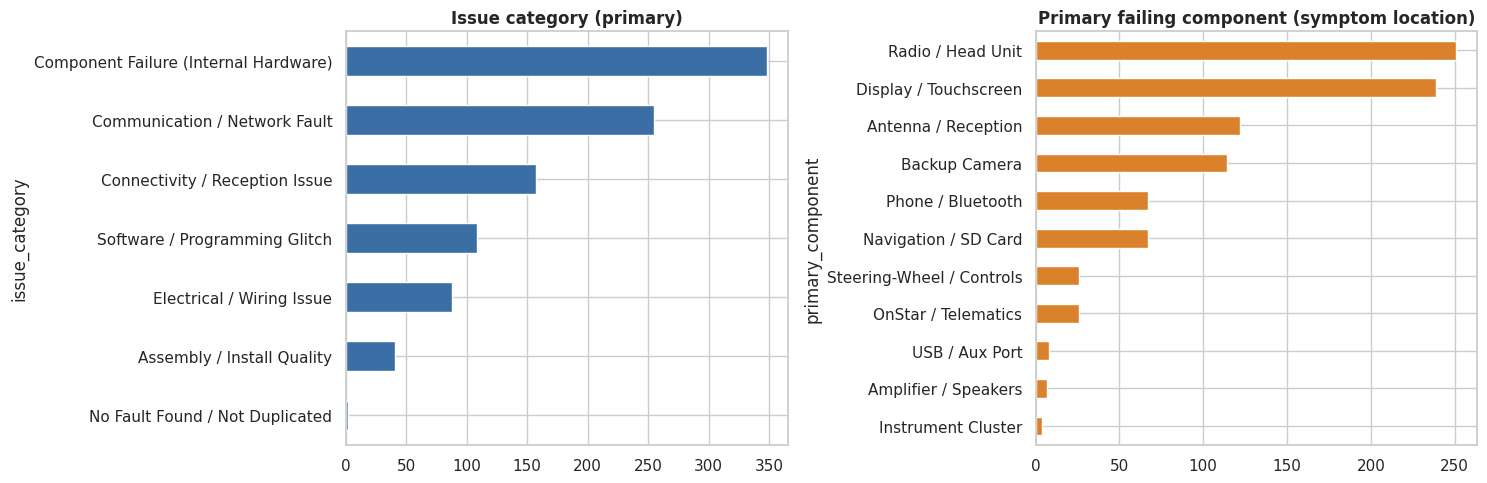

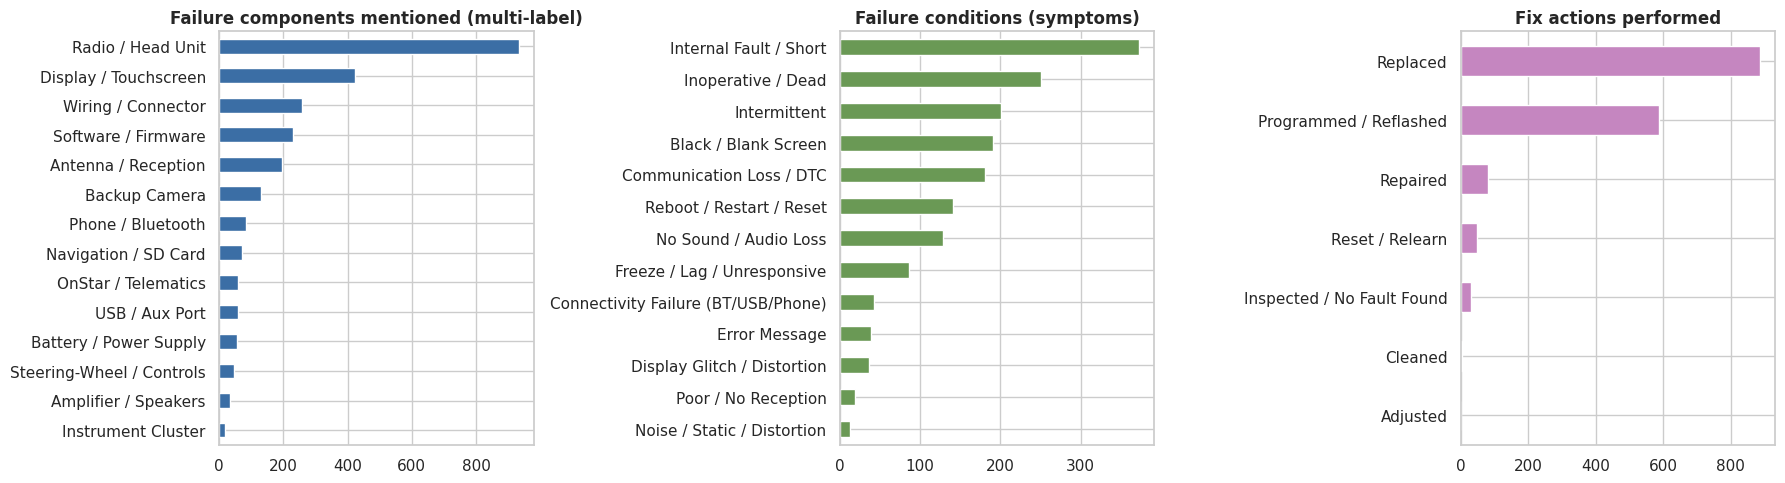

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
df.issue_category.value_counts().sort_values().plot.barh(ax=ax[0], color="#3b6ea5"); ax[0].set_title("Issue category (primary)")
df.primary_component.value_counts().sort_values().plot.barh(ax=ax[1], color="#d9822b"); ax[1].set_title("Primary failing component (symptom location)")
savefig("04_issue_categories_components"); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
flat_counts("failure_component").sort_values().plot.barh(ax=ax[0], color="#3b6ea5"); ax[0].set_title("Failure components mentioned (multi-label)")
flat_counts("failure_condition").sort_values().plot.barh(ax=ax[1], color="#6a9955"); ax[1].set_title("Failure conditions (symptoms)")
flat_counts("fix_condition").sort_values().plot.barh(ax=ax[2], color="#c586c0"); ax[2].set_title("Fix actions performed")
savefig("05_conditions_fixes"); plt.show()

## 6. Patterns and trends

open_month
2019-08-01     3
2019-09-01    12
2019-10-01    22
2019-11-01    31
2019-12-01    27
2020-01-01    67
2020-02-01    69
2020-03-01    68
2020-04-01    50
2020-05-01    64
2020-06-01    65
2020-07-01    54
2020-08-01    60
2020-09-01    45
2020-10-01    63
2020-11-01    56
2020-12-01    37
2021-01-01    39
2021-02-01    42
2021-03-01    51
2021-04-01    47
2021-05-01    27
2021-06-01     1


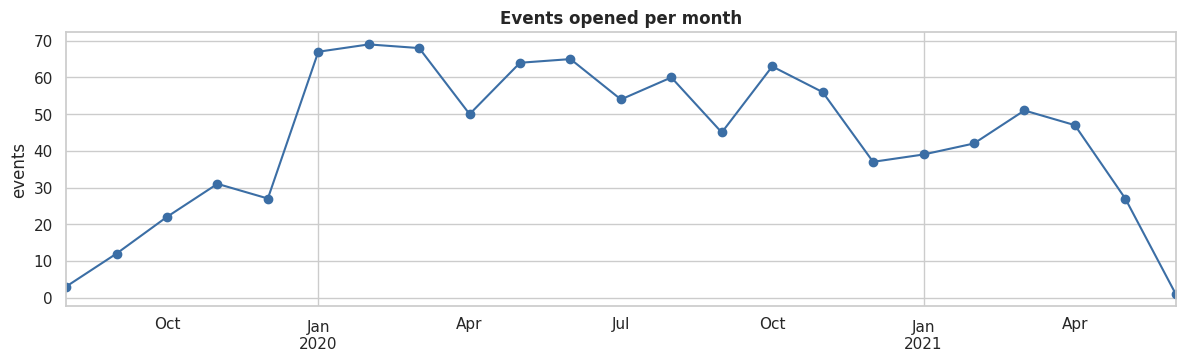

In [16]:
# 6.1 Monthly volume (by date the claim was opened)
monthly = df.groupby("open_month").size()
print(monthly.to_string())
fig, ax = plt.subplots(figsize=(12, 3.8))
monthly.plot(ax=ax, marker="o", color="#3b6ea5"); ax.set_title("Events opened per month"); ax.set_xlabel(""); ax.set_ylabel("events")
savefig("06_monthly_volume"); plt.show()

issue_category  Assembly / Install Quality  ...  Software / Programming Glitch
open_quarter                                ...                               
2019Q3                                   1  ...                              2
2019Q4                                   1  ...                             11
2020Q1                                  11  ...                             23
2020Q2                                   4  ...                             17
2020Q3                                   6  ...                             12
2020Q4                                   8  ...                             19
2021Q1                                   4  ...                             16
2021Q2                                   6  ...                              9

[8 rows x 7 columns]

Share % per quarter:
 issue_category  Assembly / Install Quality  ...  Software / Programming Glitch
open_quarter                                ...                               
2019Q3 

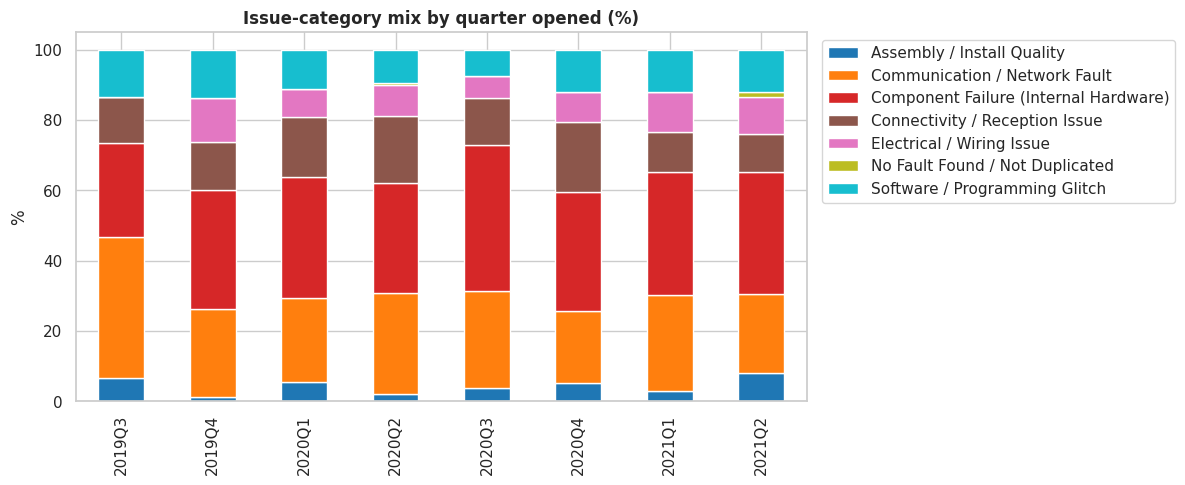

In [17]:
# 6.2 Issue category over time (share per quarter) – are some failure modes growing?
df["open_quarter"] = df.opened_date.dt.to_period("Q").astype(str)
qtab = pd.crosstab(df.open_quarter, df.issue_category)
qshare = qtab.div(qtab.sum(1), axis=0) * 100
print(qtab); print("\nShare % per quarter:\n", qshare.round(1))
qshare.plot(kind="bar", stacked=True, figsize=(12, 5), colormap="tab10"); plt.legend(bbox_to_anchor=(1.01, 1), loc="upper left"); plt.title("Issue-category mix by quarter opened (%)"); plt.ylabel("%"); plt.xlabel("")
savefig("07_category_by_quarter"); plt.show()

In [18]:
# 6.3 Statistical test for a *significant change*: first half vs second half of the observation window
mid = df.opened_date.quantile(0.5)
df["period"] = np.where(df.opened_date <= mid, "H1 (earlier)", "H2 (later)")
ct = pd.crosstab(df.issue_category, df.period)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(ct); print(f"\nChi-square H1 vs H2 category mix: chi2={chi2:.1f}, dof={dof}, p={p:.4f}")
share = ct.div(ct.sum(0), axis=1)*100; share["delta_pp"] = share["H2 (later)"] - share["H1 (earlier)"]
print(share.round(1).sort_values("delta_pp"))

period                                 H1 (earlier)  H2 (later)
issue_category                                                 
Assembly / Install Quality                       18          23
Communication / Network Fault                   130         125
Component Failure (Internal Hardware)           172         176
Connectivity / Reception Issue                   85          72
Electrical / Wiring Issue                        43          45
No Fault Found / Not Duplicated                   1           1
Software / Programming Glitch                    54          55

Chi-square H1 vs H2 category mix: chi2=1.8, dof=6, p=0.9331
period                                 H1 (earlier)  H2 (later)  delta_pp
issue_category                                                           
Connectivity / Reception Issue                 16.9        14.5      -2.4
Communication / Network Fault                  25.8        25.2      -0.7
No Fault Found / Not Duplicated                 0.2         0.2    

Plant × category chi-square p = 0.7119

Top-5 models = 54% of events:
MODEL
HyperFury X     148
TurboFlare      117
QuantumRider    109
AeroSpecter      86
NebulaJet        77


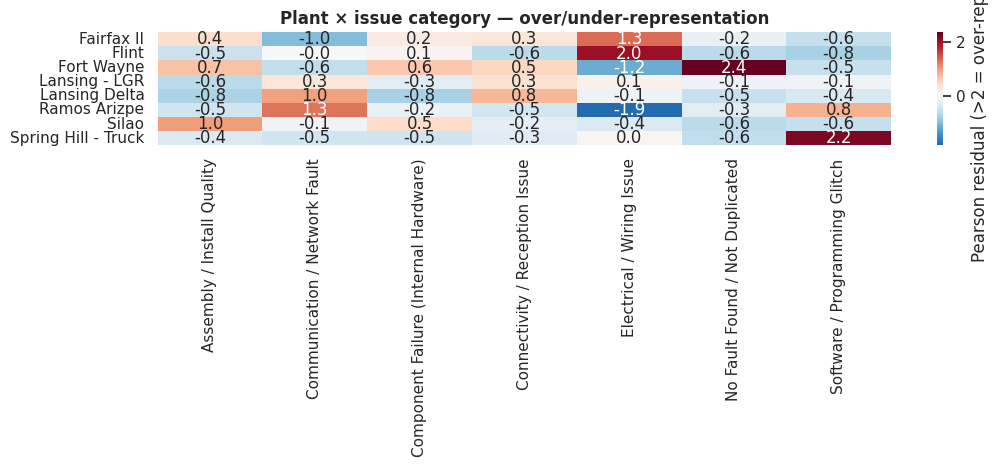

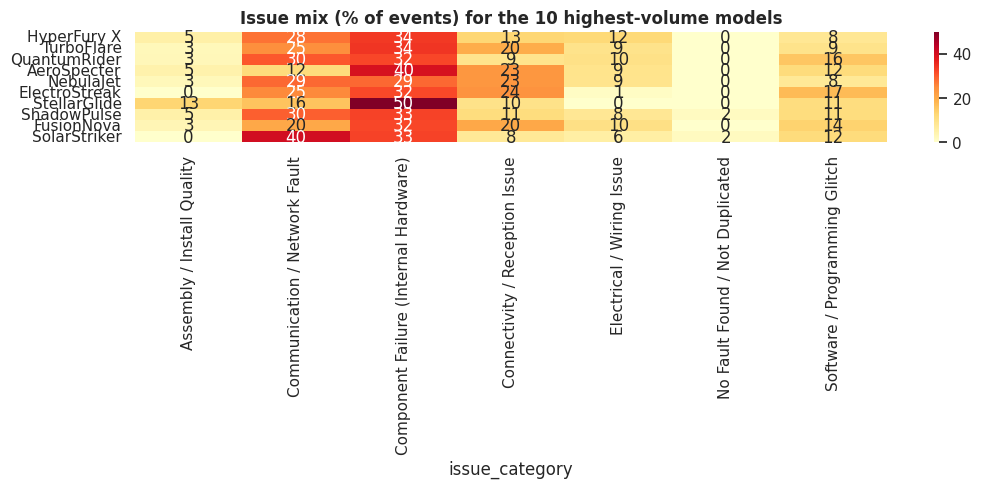

In [19]:
# 6.4 Where do failures originate?  Plant × issue category, with adjusted-residual hot-spots
pt = pd.crosstab(df.plant, df.issue_category)
chi2, p, dof, exp = stats.chi2_contingency(pt)
resid = (pt - exp) / np.sqrt(exp)          # Pearson residual > 2 ≈ significantly over-represented
print(f"Plant × category chi-square p = {p:.4f}")
plt.figure(figsize=(11, 4.8)); sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, cbar_kws={"label": "Pearson residual (>2 = over-represented)"}); plt.title("Plant × issue category — over/under-representation"); plt.ylabel(""); plt.xlabel("")
savefig("08_plant_category_heatmap"); plt.show()

# Model concentration
mt = df.MODEL.value_counts(); top5 = mt.head(5)
print(f"\nTop-5 models = {top5.sum()/len(df):.0%} of events:\n{top5.to_string()}")
mk = pd.crosstab(df.MODEL, df.issue_category).loc[mt.index[:10]]
plt.figure(figsize=(11, 5)); sns.heatmap(mk.div(mk.sum(1), axis=0)*100, annot=True, fmt=".0f", cmap="YlOrRd"); plt.title("Issue mix (% of events) for the 10 highest-volume models"); plt.ylabel("")
savefig("09_model_category_heatmap"); plt.show()

                                       count  median   mean
issue_category                                             
No Fault Found / Not Duplicated            2   180.0  180.0
Connectivity / Reception Issue           155   181.0  224.0
Assembly / Install Quality                40   202.0  222.0
Software / Programming Glitch             98   224.0  243.0
Component Failure (Internal Hardware)    321   234.0  251.0
Communication / Network Fault            224   241.0  240.0
Electrical / Wiring Issue                 84   252.0  253.0

Kruskal-Wallis across categories: H=3.7 p=0.5906

Share of events where:
mentions_dtc            14.1
mentions_tac_case       31.7
mentions_bulletin        9.5
fault_not_duplicated     2.2
part_ordered_wait        3.7

Head-unit/part replacement rate: 89%
Replacement rate when TAC/Techline was consulted: 92% vs 87% otherwise


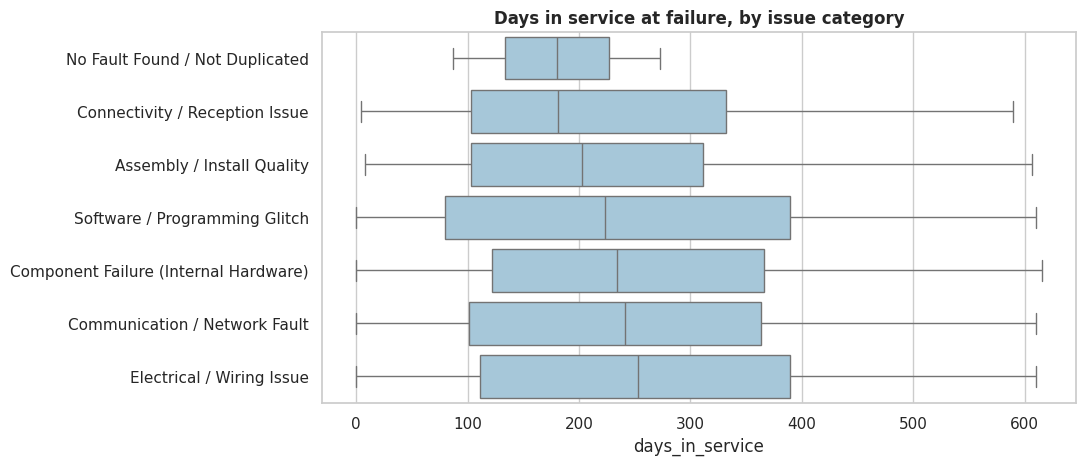

In [20]:
# 6.5 Time-in-service by issue category (early-life vs. later failures)
order = df.groupby("issue_category").days_in_service.median().sort_values().index
plt.figure(figsize=(11, 4.8)); sns.boxplot(data=df, y="issue_category", x="days_in_service", order=order, color="#9ecae1", showfliers=False); plt.title("Days in service at failure, by issue category"); plt.ylabel("")
savefig("10_tis_by_category"); plt.show()
print(df.groupby("issue_category").days_in_service.agg(["count", "median", "mean"]).round(0).sort_values("median"))
kw = stats.kruskal(*[g.days_in_service.dropna().values for _, g in df.groupby("issue_category") if g.days_in_service.notna().sum() > 5]); print("\nKruskal-Wallis across categories: H=%.1f p=%.4f" % kw)

# 6.6 Repair-process effectiveness signals
print("\nShare of events where:")
print(df[["mentions_dtc","mentions_tac_case","mentions_bulletin","fault_not_duplicated","part_ordered_wait"]].mean().mul(100).round(1).to_string())
rep = df.fix_condition.apply(lambda l: "Replaced" in l).mean(); print(f"\nHead-unit/part replacement rate: {rep:.0%}")
print("Replacement rate when TAC/Techline was consulted: %.0f%% vs %.0f%% otherwise" % (df[df.mentions_tac_case].fix_condition.apply(lambda l: "Replaced" in l).mean()*100, df[~df.mentions_tac_case].fix_condition.apply(lambda l: "Replaced" in l).mean()*100))

## 7. Clustering & topic modelling → root causes
* **K-Means on TF-IDF vectors** of the combined, cleaned narratives (customer + technician + repair).
* Domain boilerplate words (e.g. "customer states", "verified") are added to the stop-list so clusters reflect *failure content*, not report style.
* *k* is chosen by silhouette score across a candidate range (with a bias toward interpretable k).
* **LDA** is run as a second, independent view to cross-validate the clusters.

In [21]:
BOILER = set("""customer customers states stated cust says said advise advised concern vehicle veh car truck check checked found verified verify
inspect inspected please per case tac techline tech tech2 performed perform test tested testing codes code dtc dtcs set none time times need needs
will would could also then went came come comes come have has had was were are been being while after before again still just only now see seen
asked ask told tell called call contacted contact doc document sop wcc cue gds ii warranty claim labor hrs hours base diagn diagnosis diagnose diag
reports reported report customer's inspection operation operating operates ok good normal normally working work works worked start started going goes go
one two three get got into out off back time replace replaced replacement radio""".split())
ML_STOP = set("""le la les du des est pas avec pour une dans sur au aux ce cette ses son sa il elle ils et ou mais que qui ne se en de un el los las del con por para sin una al es lo su sus pero como cuando muy fonctionne probleme client cliente nous vous""".split())  # French / Spanish function words found in the corpus
STOP = list(ENGLISH_STOP_WORDS | BOILER | ML_STOP)

def prep(t):
    t = normalise(t)
    t = re.sub(r"[^a-z ]", " ", t)
    return re.sub(r"\s+", " ", t).strip()
df["clean_text"] = df.symptom_text.apply(prep)   # cluster on WHAT WENT WRONG (customer + technician diagnosis); repair notes are dominated by generic "replace radio / program" boilerplate

tfidf = TfidfVectorizer(stop_words=STOP, ngram_range=(1, 2), min_df=5, max_df=0.6, sublinear_tf=True)
X = tfidf.fit_transform(df.clean_text)
print("TF-IDF matrix:", X.shape)

TF-IDF matrix: (1000, 669)


 k  silhouette  inertia
 4      0.0261 930.7995
 5      0.0318 917.9261
 6      0.0328 912.9434
 7      0.0413 898.8158
 8      0.0447 894.8629
 9      0.0496 886.9114
10      0.0511 882.6026
11      0.0524 876.3593
12      0.0536 869.3464


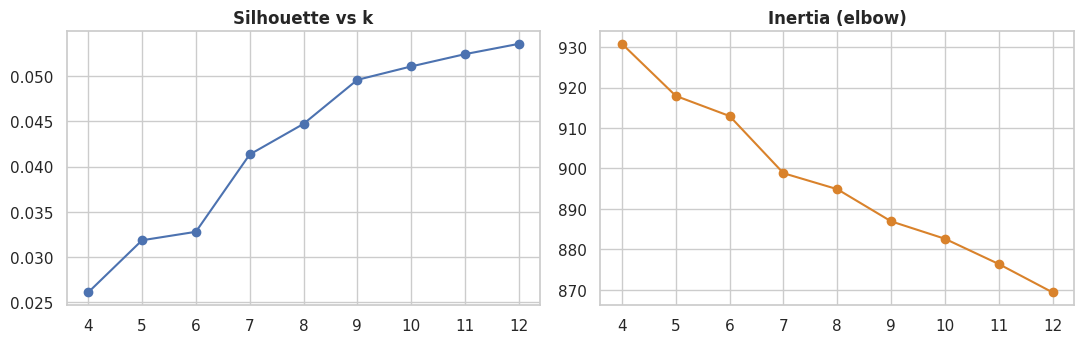

In [22]:
# Choose k: silhouette (cosine) on the TF-IDF space across k = 4..12
res = []
for k in range(4, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=RNG).fit(X)
    res.append((k, silhouette_score(X, km.labels_, metric="cosine", sample_size=1000, random_state=RNG), km.inertia_))
sel = pd.DataFrame(res, columns=["k", "silhouette", "inertia"]); print(sel.round(4).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(sel.k, sel.silhouette, marker="o"); ax[0].set_title("Silhouette vs k"); ax[1].plot(sel.k, sel.inertia, marker="o", color="#d9822b"); ax[1].set_title("Inertia (elbow)")
savefig("11_choose_k"); plt.show()

In [23]:
# Honest quality check: silhouette values are low (typical for short, noisy, jargon-heavy repair text – clusters overlap) so we also test STABILITY:
# re-run K-Means with different seeds and compare partitions (adjusted Rand index; 1.0 = identical).
from sklearn.metrics import adjusted_rand_score
base = KMeans(n_clusters=10, n_init=20, random_state=RNG).fit(X).labels_
aris = [adjusted_rand_score(base, KMeans(n_clusters=10, n_init=20, random_state=s).fit(X).labels_) for s in (1, 2, 3, 4)]
print("Seed-stability ARI (k=10):", np.round(aris, 2), "→ moderate: the *themed* clusters (SD card, Bluetooth, XM, camera) are stable; the generic screen/audio clusters are fuzzy.")

Seed-stability ARI (k=10): [0.46 0.36 0.5  0.48] → moderate: the *themed* clusters (SD card, Bluetooth, XM, camera) are stable; the generic screen/audio clusters are fuzzy.


In [24]:
K = int(os.environ.get("T2_K", 10))   # k=10 splits the big "screen/audio" blob into interpretable failure modes (SD-card, Bluetooth, XM, camera …)
km = KMeans(n_clusters=K, n_init=20, random_state=RNG).fit(X)
df["cluster"] = km.labels_
terms = np.array(tfidf.get_feature_names_out())
centroid_order = km.cluster_centers_.argsort(axis=1)[:, ::-1]
top_terms = {c: list(terms[centroid_order[c, :12]]) for c in range(K)}
print("Final k =", K, " | silhouette = %.3f" % silhouette_score(X, df.cluster, metric="cosine", sample_size=1000, random_state=RNG))
for c in range(K):
    sub = df[df.cluster == c]
    print(f"\n── Cluster {c}  (n={len(sub)}, {len(sub)/len(df):.0%}) ──")
    print("top terms :", ", ".join(top_terms[c]))
    print("issue cat :", sub.issue_category.value_counts().head(2).to_dict())
    print("causal cd :", sub.CAUSAL_CD_DESC.value_counts().head(2).to_dict())
    print("fix       :", Counter(x for l in sub.fix_condition for x in l).most_common(3))
    print("plants    :", sub.plant.value_counts(normalize=True).head(2).round(2).to_dict(), "| median days in service:", int(sub.days_in_service.median()))

Final k = 10  | silhouette = 0.051

── Cluster 0  (n=39, 4%) ──
top terms : card, sd, sd card, error, navigation, removed, card removed, message, card error, usb, internal, reader
issue cat : {'Connectivity / Reception Issue': 20, 'Component Failure (Internal Hardware)': 10}
causal cd : {'Module/Component-No/Incorrect Communication': 12, 'Module/Component-Registers Incorrectly': 10}
fix       : [('Replaced', 35), ('Programmed / Reflashed', 26), ('Repaired', 5)]
plants    : {'Silao': 0.33, 'Fort Wayne': 0.23} | median days in service: 265

── Cluster 1  (n=60, 6%) ──
top terms : phone, bluetooth, blue, tooth, blue tooth, calls, connect, pair, new, mode, contacts, demo mode
issue cat : {'Connectivity / Reception Issue': 23, 'Component Failure (Internal Hardware)': 13}
causal cd : {'Module/Component-No/Incorrect Communication': 21, 'Module/Component-Shorted': 12}
fix       : [('Replaced', 54), ('Programmed / Reflashed', 40), ('Repaired', 6)]
plants    : {'Silao': 0.28, 'Fort Wayne': 0.23}

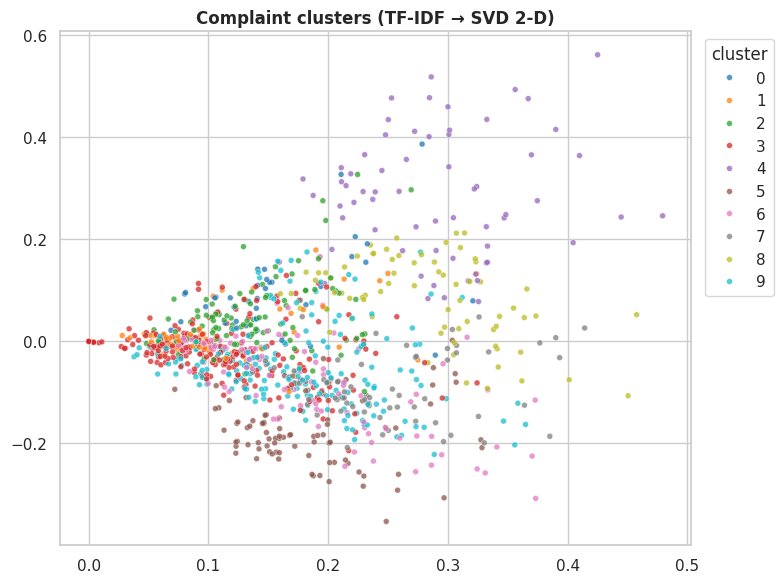

In [25]:
# 2-D visual of the clusters (SVD projection of TF-IDF)
Z = TruncatedSVD(2, random_state=RNG).fit_transform(X)
plt.figure(figsize=(8, 6)); sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=df.cluster, palette="tab10", s=18, alpha=.75); plt.title("Complaint clusters (TF-IDF → SVD 2-D)"); plt.legend(title="cluster", bbox_to_anchor=(1.01, 1))
savefig("12_cluster_scatter"); plt.show()

In [26]:
# LDA cross-check (on raw term counts)
cv = CountVectorizer(stop_words=STOP, ngram_range=(1, 1), min_df=8, max_df=0.5)
C = cv.fit_transform(df.clean_text)
lda = LatentDirichletAllocation(n_components=K, random_state=RNG, learning_method="batch", max_iter=30).fit(C)
cterms = np.array(cv.get_feature_names_out())
df["lda_topic"] = lda.transform(C).argmax(1)
for t in range(K):
    print(f"LDA topic {t} (n={int((df.lda_topic==t).sum())}):", ", ".join(cterms[lda.components_[t].argsort()[::-1][:10]]))
print("\nAgreement KMeans vs LDA (adjusted Rand index):", end=" ")
from sklearn.metrics import adjusted_rand_score; print(round(adjusted_rand_score(df.cluster, df.lda_topic), 3))

LDA topic 0 (n=206): internal, fault, screen, failure, display, module, blank, inop, power, black
LDA topic 1 (n=59): xm, signal, ck, stations, message, satellite, issues, sirius, antenna, having
LDA topic 2 (n=50): module, ground, video, ohms, circuits, id, connector, circuit, cable, terminal
LDA topic 3 (n=77): xm, signal, ro, internal, previous, stay, play, cuts, keeps, issue
LDA topic 4 (n=151): screen, camera, black, reverse, inop, intermittently, backup, rear, blank, touch
LDA topic 5 (n=111): screen, display, blank, data, volume, ground, software, power, shorted, open
LDA topic 6 (n=73): phone, card, sd, navigation, bluetooth, error, problem, onstar, wifi, message
LDA topic 7 (n=114): communication, module, screen, power, lost, ground, sound, ethernet, circuits, bus
LDA topic 8 (n=92): update, usb, software, program, failed, sps, tried, na, scan, battery
LDA topic 9 (n=67): audio, station, xm, fm, change, mode, antenna, failure, channel, internal

Agreement KMeans vs LDA (adjust

### Reading the clusters → naming & root-cause hypotheses
The cell below assigns a **human-readable label and root-cause hypothesis** to every cluster based on its top terms, dominant causal codes, fixes, plants, and time-in-service. (Labels are set after inspecting the output above; they are data-driven, not assumed.)

 cluster                                     cluster_label  events  median_days_in_service  replace_rate  tac_rate  nff_rate           top_plant  top_plant_share                                  top_causal  share_pct
       0                  Navigation / SD-card read errors      39                   265.0          0.90      0.46      0.00               Silao             0.33 Module/Component-No/Incorrect Communication        3.9
       1                    Phone / Bluetooth connectivity      60                   184.5          0.90      0.43      0.05               Silao             0.28 Module/Component-No/Incorrect Communication        6.0
       2                    XM / radio reception & antenna     106                   163.0          0.91      0.38      0.03 Spring Hill - Truck             0.21 Module/Component-No/Incorrect Communication       10.6
       3    General screen / audio malfunction (catch-all)     214                   229.5          0.87      0.36      0.04        

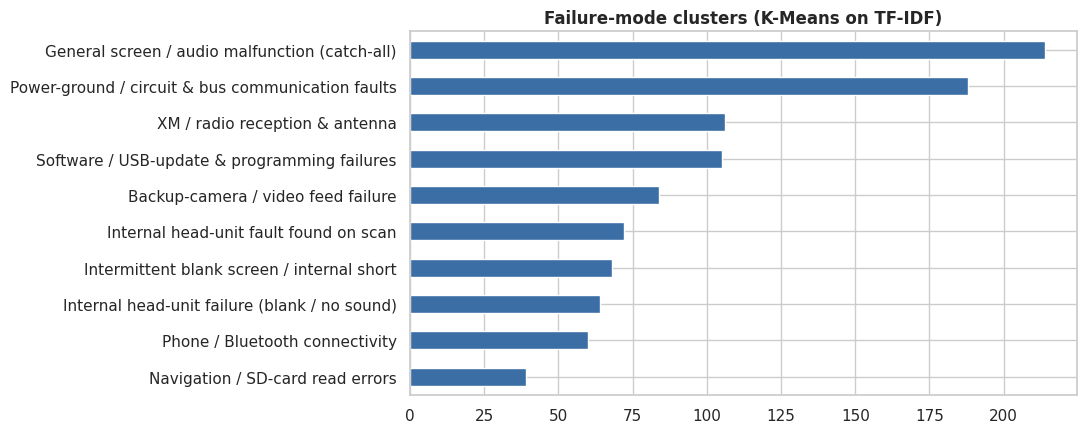

In [27]:
def auto_label(c):
    """Rule-based naming from each cluster's top-8 TF-IDF terms (checked manually against the printed terms above)."""
    tt = " ".join(top_terms[c][:8])
    rules = [
        (r"sd card|card removed", "Navigation / SD-card read errors"),
        (r"bluetooth|phone|blue tooth", "Phone / Bluetooth connectivity"),
        (r"\bxm\b|sirius|antenna|signal|stations", "XM / radio reception & antenna"),
        (r"camera|rear|backup", "Backup-camera / video feed failure"),
        (r"internal fault|scan", "Internal head-unit fault found on scan"),
        (r"update|software|program", "Software / USB-update & programming failures"),
        (r"ground|circuit|ethernet|voltage", "Power-ground / circuit & bus communication faults"),
        (r"internal failure|\bfailure\b", "Internal head-unit failure (blank / no sound)"),
        (r"blank|shorted", "Intermittent blank screen / internal short"),
    ]
    for pat, lab in rules:
        if re.search(pat, tt): return lab
    return "General screen / audio malfunction (catch-all)"
labels = {c: auto_label(c) for c in range(K)}
# make labels unique by appending the leading term if duplicated
seen = Counter()
for c in range(K):
    seen[labels[c]] += 1
    if seen[labels[c]] > 1: labels[c] += f" (variant: {top_terms[c][0]})"
df["cluster_label"] = df.cluster.map(labels)
profile = (df.groupby(["cluster", "cluster_label"]).agg(events=("Event id", "count"),
            median_days_in_service=("days_in_service", "median"),
            replace_rate=("fix_condition", lambda s: np.mean(["Replaced" in l for l in s])),
            tac_rate=("mentions_tac_case", "mean"), nff_rate=("fault_not_duplicated", "mean"),
            top_plant=("plant", lambda s: s.value_counts().index[0]),
            top_plant_share=("plant", lambda s: s.value_counts(normalize=True).iloc[0]),
            top_causal=("CAUSAL_CD_DESC", lambda s: s.value_counts().index[0])).round(2).reset_index())
profile["top_terms"] = profile.cluster.map(lambda c: ", ".join(top_terms[c][:8]))
profile["share_pct"] = (profile.events / len(df) * 100).round(1)
print(profile.drop(columns="top_terms").to_string(index=False))

plt.figure(figsize=(11, 4.5)); df.cluster_label.value_counts().sort_values().plot.barh(color="#3b6ea5"); plt.title("Failure-mode clusters (K-Means on TF-IDF)"); plt.ylabel("")
savefig("13_cluster_sizes"); plt.show()

Cluster × plant chi-square p = 0.3365

Cluster × issue-category (rule-based) — consistency check:
 issue_category                                     Assembly / Install Quality  ...  Software / Programming Glitch
cluster_label                                                                  ...                               
Backup-camera / video feed failure                                         10  ...                              5
General screen / audio malfunction (catch-all)                             13  ...                             20
Intermittent blank screen / internal short                                  0  ...                              8
Internal head-unit failure (blank / no sound)                               1  ...                              3
Internal head-unit fault found on scan                                      1  ...                              3
Navigation / SD-card read errors                                            3  ...                     

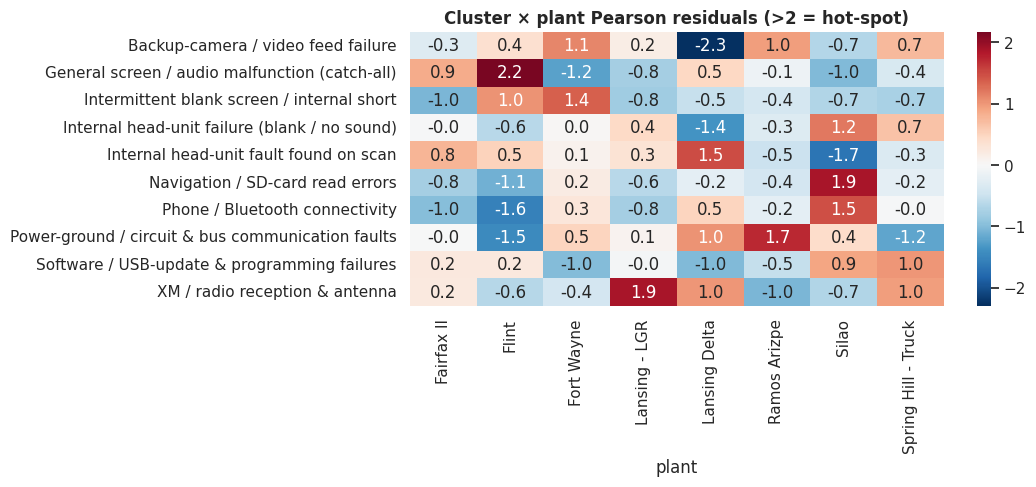

In [28]:
# Cluster × plant over-representation (does a failure mode concentrate in a plant?)
cp = pd.crosstab(df.cluster_label, df.plant)
chi2, p, dof, exp = stats.chi2_contingency(cp); print(f"Cluster × plant chi-square p = {p:.4f}")
plt.figure(figsize=(11, 5)); sns.heatmap((cp-exp)/np.sqrt(exp), annot=True, fmt=".1f", cmap="RdBu_r", center=0); plt.title("Cluster × plant Pearson residuals (>2 = hot-spot)"); plt.ylabel("")
savefig("14_cluster_plant"); plt.show()
cm = pd.crosstab(df.cluster_label, df.issue_category); print("\nCluster × issue-category (rule-based) — consistency check:\n", cm)

## 8. Root-cause synthesis (generated from the data above)

In [29]:
top_cat = df.issue_category.value_counts()
comp_counts = flat_counts("failure_component")
print("TOP FINDINGS")
print(f"1. {top_cat.index[0]} is the #1 issue type ({top_cat.iloc[0]/len(df):.0%}); next: {top_cat.index[1]} ({top_cat.iloc[1]/len(df):.0%}).")
print(f"2. 'Radio / Head Unit' appears in {comp_counts['Radio / Head Unit']/len(df):.0%} of narratives; 'Display / Touchscreen' in {comp_counts['Display / Touchscreen']/len(df):.0%}.")
print(f"3. Median time-in-service at failure = {df.days_in_service.median():.0f} days; {(tis<=90).mean():.0%} fail within 90 days, {(tis<=180).mean():.0%} within 180 days. {df.opened_before_in_use.mean():.1%} of claims were opened before the in-service date.")
print(f"4. {df.fix_condition.apply(lambda l: 'Replaced' in l).mean():.0%} of repairs end in a part replacement; only {df.fix_condition.apply(lambda l: 'Programmed / Reflashed' in l).mean():.0%} involve reprogramming.")
print(f"5. {df.fault_not_duplicated.mean():.0%} of events are 'could not duplicate / no fault found' – diagnostic-process leakage.")
print(f"6. Top-5 models account for {top5.sum()/len(df):.0%} of events; top-3 plants {df.plant.value_counts(normalize=True).head(3).sum():.0%}.")

TOP FINDINGS
1. Component Failure (Internal Hardware) is the #1 issue type (35%); next: Communication / Network Fault (26%).
2. 'Radio / Head Unit' appears in 93% of narratives; 'Display / Touchscreen' in 42%.
3. Median time-in-service at failure = 228 days; 21% fail within 90 days, 43% within 180 days. 7.6% of claims were opened before the in-service date.
4. 89% of repairs end in a part replacement; only 59% involve reprogramming.
5. 2% of events are 'could not duplicate / no fault found' – diagnostic-process leakage.
6. Top-5 models account for 54% of events; top-3 plants 62%.


## 9. Exports — updated dataset with tags and categories

In [30]:
OUT = os.environ.get("T2_OUT", ".")
j = lambda l: "; ".join(l)
export = df.copy()
for c in ["failure_component", "failure_condition", "trigger", "additional_context", "fix_component", "fix_condition"]:
    export[c] = export[c].apply(j)
export_cols = ["Event id", "opened_date", "MAKE", "MODEL", "plant", "COMPLAINT_CD_DESC", "CAUSAL_CD_DESC", "causal_family",
               "CUSTOMER_VERBATIM", "CAUSAL_VERBATIM", "CORRECTION_VERBATIM", "build_date", "in_use_date", "days_in_service", "opened_before_in_use", "language",
               "failure_component", "primary_component", "failure_condition", "trigger", "additional_context", "fix_component", "fix_condition",
               "issue_category", "cluster", "cluster_label", "lda_topic", "mentions_dtc", "mentions_bulletin", "mentions_tac_case", "fault_not_duplicated", "part_ordered_wait",
               "in_use_imputed_flag", "causal_imputed_flag", "customer_text_is_placeholder"]
export = export[export_cols].rename(columns={"failure_component": "Failure Component", "failure_condition": "Failure Condition", "trigger": "Trigger",
                                               "additional_context": "Additional Context", "fix_component": "Fix Component", "fix_condition": "Fix Condition",
                                               "primary_component": "Primary Component", "issue_category": "Issue Category", "cluster": "Cluster ID", "cluster_label": "Cluster Label", "lda_topic": "LDA Topic"})
export.to_csv(f"{OUT}/Task2_tagged_dataset.csv", index=False)

with pd.ExcelWriter(f"{OUT}/Task2_tagged_dataset.xlsx", engine="openpyxl") as xw:
    export.to_excel(xw, sheet_name="Tagged_Data", index=False)
    top_cat.rename("events").to_frame().assign(pct=lambda x: (x.events/len(df)*100).round(1)).to_excel(xw, sheet_name="Issue_Categories")
    pd.DataFrame({tag: flat_counts(tag) for tag in ["failure_component", "failure_condition", "fix_condition"]}).fillna(0).astype(int).to_excel(xw, sheet_name="Entity_Counts")
    profile.to_excel(xw, sheet_name="Cluster_Profile", index=False)
    qtab.to_excel(xw, sheet_name="Category_by_Quarter")
    pt.to_excel(xw, sheet_name="Plant_x_Category")
print("Saved:", export.shape, "→ Task2_tagged_dataset.csv / .xlsx")
export.head(3).T

Saved: (1000, 35) → Task2_tagged_dataset.csv / .xlsx
